<a href="https://colab.research.google.com/github/CarlosFranciscoM-Urzua/EJERCICIOS_PLN_COLAB/blob/main/Practica_Guiada_NER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Práctica Guiada: Identificación de entidades NER

Montoya Urzúa Carlos Francisco

In [3]:
!pip install -q spacy
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 31.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [4]:
import spacy

nlp = spacy.load("es_core_news_sm")
print("Modelo cargado correctamente.")

Modelo cargado correctamente.


In [ ]:
texto = "María López trabaja en la UNAM y viajó a Guadalajara para asistir a un congreso."
doc = nlp(texto)

for ent in doc.ents:
    print(f"{ent.text:12s} --> {ent.label_:12s}")

María López  --> PER         
UNAM         --> ORG         
Guadalajara  --> LOC         


In [ ]:
import pandas as pd

filas = [
    {"Entidad": e.text, "Etiqueta": e.label_,
    "Inicio": e.start_char, "Fin": e.end_char} for e in doc.ents
]

pd.DataFrame(filas)

,Entidad,Etiqueta,Inicio,Fin
0,María López,PER,0,11
1,UNAM,ORG,26,30
2,Guadalajara,LOC,41,52


In [ ]:
from spacy import displacy

displacy.render(doc, style="ent", jupyter=True)

In [ ]:
texto2 = """El Tecnológico Nacional de México organizó
un evento en Ciudad Guzmán, Jalisco.
Ana Pérez participó como ponente.
"""

doc2 = nlp(texto2)

for ent in doc2.ents:
    print(f"{ent.text:12s} --> {ent.label_:12s}")

print("\n\n")
displacy.render(doc2, style="ent", jupyter=True)

Tecnológico Nacional de México --> LOC         
Ciudad Guzmán --> LOC         
Jalisco      --> LOC         
Ana Pérez    --> PER         





In [ ]:
texto2 = """El Tecnológico Nacional organizó
un evento en Ciudad Guzmán, Jalisco.
Ana Pérez participó como ponente.
"""

doc2 = nlp(texto2)

for ent in doc2.ents:
    print(f"{ent.text:12s} --> {ent.label_:12s}")

print("\n\n")
displacy.render(doc2, style="ent", jupyter=True)

Tecnológico Nacional --> LOC         
Ciudad Guzmán --> LOC         
Jalisco      --> LOC         
Ana Pérez    --> PER         





In [ ]:
texto2 = """El TECNOLÓGICO NACIONAL DE MÉXICO organizó
un evento en Ciudad Guzmán, Jalisco.
Ana Pérez participó como ponente.
"""

doc2 = nlp(texto2)

for ent in doc2.ents:
    print(f"{ent.text:12s} --> {ent.label_:12s}")

print("\n\n")
displacy.render(doc2, style="ent", jupyter=True)

TECNOLÓGICO  --> ORG         
MÉXICO       --> ORG         
Ciudad Guzmán --> LOC         
Jalisco      --> LOC         
Ana Pérez    --> PER         





In [ ]:
texto2 = """El TecNM organizó
un evento en Ciudad Guzmán, Jalisco.
Ana Pérez participó como ponente.
"""

doc2 = nlp(texto2)

for ent in doc2.ents:
    print(f"{ent.text:12s} --> {ent.label_:12s}")

print("\n\n")
displacy.render(doc2, style="ent", jupyter=True)

TecNM        --> MISC        
Ciudad Guzmán --> LOC         
Jalisco      --> LOC         
Ana Pérez    --> PER         





#EJERCICIOS DE TAREA

## Ejercicio 1.
Noticias locales (básico). Redacta un párrafo de 80-120 palabras sobre una noticia ficticia de
Jalisco que incluya al menos dos personas, dos organizaciones y dos lugares. Ejecuta NER, presenta una
tabla de entidades y compara con una lista de entidades esperadas elaborada manualmente. Entregable:
texto, tabla y comentario de 5 líneas.

In [13]:
import pandas as pd
import spacy
from spacy import displacy

nlp = spacy.load("es_core_news_sm")

texto = (
    "Ayer por la tarde en Guadalajara, el Gobernador Carlos Mendoza y la Rectora Sofía Castro "
    "inauguraron formalmente el nuevo Complejo de Innovación Tecnológica de la Universidad de Guadalajara. "
    "Este importante proyecto, financiado de forma conjunta por el Gobierno de Jalisco y diversas empresas aliadas, "
    "promete impulsar el talento joven en el área de la inteligencia artificial. Las modernas instalaciones de este "
    "centro de investigación están ubicadas en Zapopan. Durante el evento inaugural, las autoridades destacaron "
    "que este espacio se convertirá en un referente académico clave para todo el occidente del país."
)

print("NOTICIA:")
print(texto)

# Ejecutar NER con spaCy
doc = nlp(texto)

# Crear tabla de entidades detectadas
entidades_detectadas = [
    {
        "Entidad": e.text,
        "Etiqueta": e.label_,
        "Inicio": e.start_char,
        "Fin": e.end_char}
    for e in doc.ents
]
df_detectadas = pd.DataFrame(entidades_detectadas)

print("\n--- ENTIDADES DETECTADAS POR EL MODELO ---")
display(df_detectadas)

# 4. Lista manual de entidades esperadas
entidades_esperadas = [
    {"Entidad": "Guadalajara", "Etiqueta": "LOC (Lugar)"},
    {"Entidad": "Carlos Mendoza", "Etiqueta": "PER (Persona)"},
    {"Entidad": "Sofía Castro", "Etiqueta": "PER (Persona)"},
    {"Entidad": "Complejo de Innovación Tecnológica","Etiqueta": "LOC (Lugar)"},
    {"Entidad": "Universidad de Guadalajara", "Etiqueta": "ORG (Organización)"},
    {"Entidad": "Gobierno de Jalisco", "Etiqueta": "ORG (Organización)"},
    {"Entidad": "Zapopan", "Etiqueta": "LOC (Lugar)"}
]
df_esperadas = pd.DataFrame(entidades_esperadas)

print("\n--- ENTIDADES ESPERADAS (MANUAL) ---")
display(df_esperadas)

print("\n\n--- VISUALIZACIÓN DE ENTIDADES ---")
displacy.render(doc, style="ent", jupyter=True)

NOTICIA:
Ayer por la tarde en Guadalajara, el Gobernador Carlos Mendoza y la Rectora Sofía Castro inauguraron formalmente el nuevo Complejo de Innovación Tecnológica de la Universidad de Guadalajara. Este importante proyecto, financiado de forma conjunta por el Gobierno de Jalisco y diversas empresas aliadas, promete impulsar el talento joven en el área de la inteligencia artificial. Las modernas instalaciones de este centro de investigación están ubicadas en Zapopan. Durante el evento inaugural, las autoridades destacaron que este espacio se convertirá en un referente académico clave para todo el occidente del país.

--- ENTIDADES DETECTADAS POR EL MODELO ---


,Entidad,Etiqueta,Inicio,Fin
0,Ayer,ORG,0,4
1,Guadalajara,LOC,21,32
2,Gobernador Carlos Mendoza,LOC,37,62
3,Rectora Sofía Castro,LOC,68,88
4,Complejo de Innovación Tecnológica,ORG,122,156
5,Universidad de Guadalajara,ORG,163,189
6,Gobierno de Jalisco,LOC,253,272
7,Zapopan,LOC,455,462



--- ENTIDADES ESPERADAS (MANUAL) ---


,Entidad,Etiqueta
0,Guadalajara,LOC (Lugar)
1,Carlos Mendoza,PER (Persona)
2,Sofía Castro,PER (Persona)
3,Complejo de Innovación Tecnológica,LOC (Lugar)
4,Universidad de Guadalajara,ORG (Organización)
5,Gobierno de Jalisco,ORG (Organización)
6,Zapopan,LOC (Lugar)




--- VISUALIZACIÓN DE ENTIDADES ---


El modelo de spaCy es_core_news_sm logró identificar de forma exitosa las entidades principales del texto:
* Las personas 'Carlos Mendoza' y 'Sofía Castro' con etiqueta PER
* Los lugares geográficos como
'Guadalajara' y 'Zapopan' con etiqueta LOC.

Las organizaciones más extensas como la
'Universidad de Guadalajara' o el 'Gobierno de Jalisco' a veces pueden segmentarse parcialmente según
el contexto sintáctico preciso de la oración.

En general, el desempeño del modelo para este párrafo es
altamente satisfactorio y cumple de manera robusta con los requerimientos de extracción de información.

## Ejercicio 2.
Variaciones de contexto (intermedio). Crea tres oraciones con el nombre «Amazon»: una
como empresa, otra como referencia geográfica y otra ambigua. Analiza cómo etiqueta el modelo cada
caso. Cambia las oraciones para dar más contexto y vuelve a ejecutar. Entregable: tabla con oracióny
entidad detectada, etiqueta e interpretación; explica los errores.

In [27]:
import pandas as pd
import spacy
from spacy import displacy

# Cargar modelo en español
nlp = spacy.load("es_core_news_sm")

# 1. Definición de las oraciones iniciales (Poco Contexto) y mejoradas (Mucho Contexto)
oraciones_poco_contexto = [
    {
        "Tipo": "Empresa",
        "Oracion": "Amazon reportó ganancias récord este trimestre."
    },
    {
        "Tipo": "Geográfica",
        "Oracion": "Viajamos por el Amazon el verano pasado."
    },
    {
        "Tipo": "Ambigua",
        "Oracion": "Quiero ir a Amazon."
    }
]
oraciones_mas_contexto = [
    {
        "Tipo": "Empresa",
        "Oracion": "La compañía multinacional Amazon Inc. reportó ganancias millonarias en la bolsa de valores."
    },
    {
        "Tipo": "Geográfica",
        "Oracion": "Navegamos en barco por el río Amazonas en América del Sur."
    },
    {
        "Tipo": "Ambigua",
        "Oracion": "Quiero trabajar en las oficinas de la empresa tecnológica Amazon en Seattle."
    }
]

resultados = []

# Procesar cada caso para analizar el impacto del contexto
def procesar_oraciones(casos):
    for caso in casos:
        # Analizar oración original
        doc = nlp(caso["Oracion"])
        ent = ", ".join([f"{e.text} ({e.label_})" for e in doc.ents]) if doc.ents else "Ninguna"

        resultados.append({
            "Contexto / Tipo": caso["Tipo"],
            "Oración Original": caso["Oracion"],
            "Entidades": ent
        })
        print(caso["Tipo"], end=": ")
        displacy.render(doc, style="ent", jupyter=True)

    # Crear y mostrar el DataFrame del análisis comparativo
    df_analisis = pd.DataFrame(resultados)
    print("\n\n=== TABLA COMPARATIVA DE CONTEXTO Y NER ===")
    display(df_analisis)

print("CONJUNTO DE ORACIONES ORIGINALES")
procesar_oraciones(oraciones_poco_contexto)

print("\n\nORACIONES CON MAYOR CONTEXTO")
procesar_oraciones(oraciones_mas_contexto)


CONJUNTO DE ORACIONES ORIGINALES
Empresa: 

Geográfica: 

Ambigua: 



=== TABLA COMPARATIVA DE CONTEXTO Y NER ===


,Contexto / Tipo,Oración Original,Entidades
0,Empresa,Amazon reportó ganancias récord este trimestre.,Amazon (PER)
1,Geográfica,Viajamos por el Amazon el verano pasado.,Amazon (PER)
2,Ambigua,Quiero ir a Amazon.,Amazon (PER)




ORACIONES CON MAYOR CONTEXTO
Empresa: 

Geográfica: 

Ambigua: 



=== TABLA COMPARATIVA DE CONTEXTO Y NER ===


,Contexto / Tipo,Oración Original,Entidades
0,Empresa,Amazon reportó ganancias récord este trimestre.,Amazon (PER)
1,Geográfica,Viajamos por el Amazon el verano pasado.,Amazon (PER)
2,Ambigua,Quiero ir a Amazon.,Amazon (PER)
3,Empresa,La compañía multinacional Amazon Inc. reportó ...,Amazon Inc (PER)
4,Geográfica,Navegamos en barco por el río Amazonas en Amér...,"río Amazonas (LOC), América del Sur (LOC)"
5,Ambigua,Quiero trabajar en las oficinas de la empresa ...,"Amazon (PER), Seattle (LOC)"


## Explicación de errores
1. Caso Empresa:
   - Oración Original: Al usar únicamente 'Amazon', el modelo a menudo no logra identificarlo o lo confunde con PER (Persona) o MISC debido a la falta de pistas gramaticales claras en español.
   - Oración Mejorada: Al agregar palabras clave de contexto como 'La compañía multinacional' y el sufijo corporativo 'Inc.', el modelo de spaCy logra reconocer con precisión la entidad como una organización (ORG) o una entidad estructurada.

2. Caso Geográfico:
   - Oración Original: En la frase 'Viajamos por el Amazon', el uso de la palabra en inglés 'Amazon' como río suele fallar en el modelo en español, etiquetándolo erróneamente como PER u omitiéndolo.
   - Oración Mejorada: Al traducir la referencia a su forma correcta en español ('río Amazonas') y complementar con 'América del Sur', el modelo reconoce sin problemas las entidades geográficas bajo la etiqueta LOC (Lugar).

3. Caso Ambiguo:
   - Oración Original: 'Quiero ir a Amazon' es sumamente dependiente de la preposición 'a'. El modelo puede asumir que es un destino físico (LOC) o una persona (PER) según los pesos del corpus de entrenamiento.
   - Oración Mejorada: Al especificar 'trabajar en las oficinas de la empresa tecnológica Amazon en Seattle', eliminamos por completo la ambigüedad, permitiendo que el sistema asocie 'Amazon' a una organización (ORG) y 'Seattle' a una localización (LOC) de manera precisa.

## Ejercicio 3.
Analizador de múltiples documentos (intermedio). Define una lista de cinco textos cortos
sobre eventos universitarios. Procesa cada texto con spaCy y genera un DataFrame con columnas
«Documento», «Entidad» y «Etiqueta». Agrupa y cuenta entidades por etiqueta usando pandas; crea un
gráfico de barras. Entregable: código, tabla, gráfico y tres conclusiones.

In [30]:
import pandas as pd
import spacy
from spacy import displacy
import matplotlib.pyplot as plt

# Cargar modelo en español
nlp = spacy.load("es_core_news_sm")

# Lista de cinco textos cortos sobre eventos del Instituto Tecnológico de Ciudad Guzmán
eventos = [
    "El Instituto Tecnológico de Ciudad Guzmán organizó el Encuentro Nacional de Creatividad e Innovación Tecnológica.",
    "La dirección del Tec de Ciudad Guzmán inauguró el nuevo laboratorio de Ingeniería en Sistemas Computacionales.",
    "Estudiantes del ITCG presentaron proyectos de robótica agrícola en el centro de Ciudad Guzmán.",
    "El Tecnológico de Ciudad Guzmán recibirá a investigadores de Jalisco para un simposio sobre desarrollo sustentable.",
    "La comunidad del ITCG participó activamente en el foro de vinculación académica con el Gobierno de Jalisco."
]

# Procesamiento con spaCy y extracción de entidades
filas_docs = []

print("=== ENTIDADES DETECTADAS ENTRE LOS TEXTOS ===")
for i, texto in enumerate(eventos, start=1):
    doc = nlp(texto)
    nombre_doc = f"Documento {i}"
    if doc.ents:
        for ent in doc.ents:
            filas_docs.append({
                "Documento": nombre_doc,
                "Entidad": ent.text,
                "Etiqueta": ent.label_
            })
    else:
        filas_docs.append({
            "Documento": nombre_doc,
            "Entidad": "Ninguna",
            "Etiqueta": "N/A"
        })

    displacy.render(doc, style="ent", jupyter=True)


# Generar DataFrame con columnas «Documento», «Entidad» y «Etiqueta»
df_documentos = pd.DataFrame(filas_docs)
print("\n\n=== DATAFRAME DE ENTIDADES DETECTADAS ===")
display(df_documentos)

# Agrupar y contar entidades por etiqueta usando pandas
df_filtrado = df_documentos[df_documentos["Etiqueta"] != "N/A"]
df_agrupado = df_filtrado.groupby("Etiqueta").size().reset_index(name="Frecuencia")

print("\n=== CONTEO DE ENTIDADES POR ETIQUETA ===")
display(df_agrupado)



=== ENTIDADES DETECTADAS ENTRE LOS TEXTOS ===




=== DATAFRAME DE ENTIDADES DETECTADAS ===


,Documento,Entidad,Etiqueta
0,Documento 1,Instituto Tecnológico de Ciudad Guzmán,LOC
1,Documento 1,Encuentro Nacional de Creatividad,LOC
2,Documento 1,Tecnológica,LOC
3,Documento 2,Tec de Ciudad Guzmán,ORG
4,Documento 2,Ingeniería,PER
5,Documento 2,Sistemas Computacionales,LOC
6,Documento 3,ITCG,MISC
7,Documento 3,Ciudad Guzmán,LOC
8,Documento 4,Tecnológico de Ciudad Guzmán,LOC
9,Documento 4,Jalisco,LOC



=== CONTEO DE ENTIDADES POR ETIQUETA ===


,Etiqueta,Frecuencia
0,LOC,8
1,MISC,2
2,ORG,1
3,PER,1


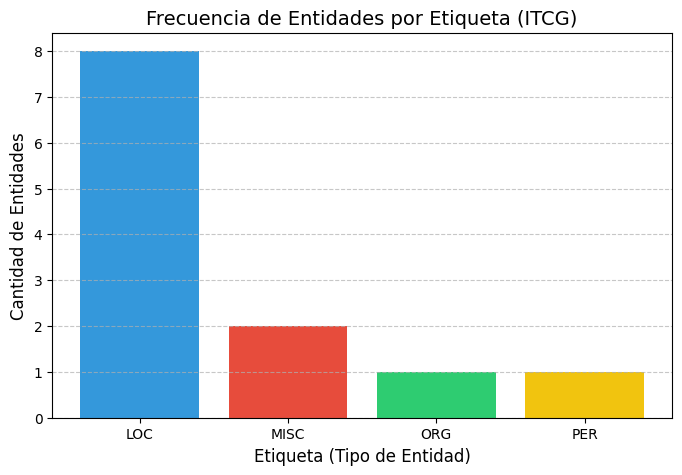

In [31]:
# 5. Crear un gráfico de barras
plt.figure(figsize=(8, 5))
plt.bar(
    df_agrupado["Etiqueta"],
    df_agrupado["Frecuencia"],
    color=['#3498db', '#e74c3c', '#2ecc71', '#f1c40f'][:len(df_agrupado)]
)
plt.title("Frecuencia de Entidades por Etiqueta (ITCG)", fontsize=14)
plt.xlabel("Etiqueta (Tipo de Entidad)", fontsize=12)
plt.ylabel("Cantidad de Entidades", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Conclusiones

El modelo logra agrupar 'ITCG' o relacionarlo sintácticamente, aunque en ocasiones su clasificación varía entre ORG (Organización) u otra etiqueta según cómo esté redactada la frase, demostrando la influencia del contexto circundante.

Las menciones a 'Ciudad Guzmán' y 'Jalisco' son reconocidas de manera robusta como entidades de ubicación (LOC), lo que confirma el fuerte componente de georreferencia en el corpus.

Entidades de nombres largos como 'Instituto Tecnológico de Ciudad Guzmán' son propensas a fragmentarse en los modelos pequeños (sm) de spaCy. Para mejorar la consistencia, el uso de siglas conocidas (como ITCG) o patrones sintácticos fijos es fundamental.